In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

<>:476: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
<>:476: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
C:\Users\derNarr.v0\AppData\Local\Temp\ipykernel_8864\2292735504.py:476: SyntaxWarning: "\%" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\%"? A raw string is also an option.
  ax_res.set_ylabel("Error relativo porcentual \n respecto al ajuste (\%)")


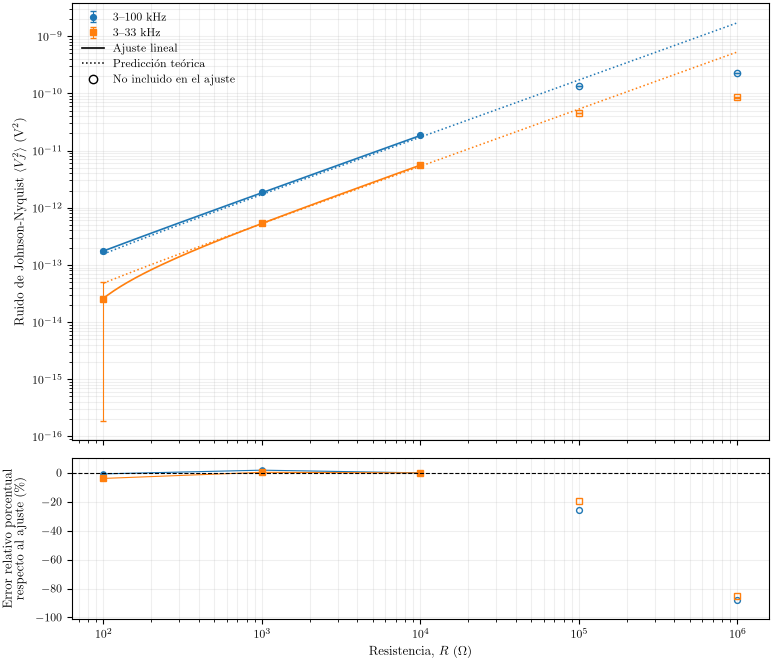

Ajustes ponderados usando únicamente la repetibilidad estadística:

3–100 kHz: k_B = (1.4737 +/- 0.0011) x 10^-23 J/K, R^2 = 0.999994, chi2_red = 0.678, diferencia = +6.74%
3–33 kHz: k_B = (1.4528 +/- 0.0018) x 10^-23 J/K, R^2 = 1.000000, chi2_red = 0.361, diferencia = +5.23%

Archivos generados:
  C:\Users\derNarr.v0\Downloads\constant_temperature_processed_v2.csv
  C:\Users\derNarr.v0\Downloads\constant_temperature_fit_summary_v2.csv
  C:\Users\derNarr.v0\Downloads\constant_temperature_resistance_all_points.png

Las incertidumbres del ajuste incluyen la repetibilidad estadística y la incertidumbre estadística compartida de la referencia de 10 ohm. No incluyen todavía las incertidumbres sistemáticas de ganancia, ENBW, resistencia o temperatura.


In [ ]:

BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

DATA_FILE = BASE_DIR / "constant_temperature_data.csv"
OUTPUT_FIGURE = BASE_DIR / "constant_temperature_resistance_all_points.png"
OUTPUT_SUMMARY = BASE_DIR / "constant_temperature_fit_summary_v2.csv"
OUTPUT_PROCESSED = BASE_DIR / "constant_temperature_processed_v2.csv"

K_B_REF = 1.380649e-23  # J/K, exact SI value
BASELINE_R_OHM = 10.0   # ohm
FIT_R_MIN = 100.0       # ohm
FIT_R_MAX = 1.0e4       # ohm
SHOW_FIGURE = True

SELECTED_BANDS = ["3 kHz - 100 kHz", "3 kHz - 33 kHz",]

BAND_LABELS = {"3 kHz - 100 kHz": "3–100 kHz", "3 kHz - 33 kHz": "3–33 kHz",}

REQUIRED_COLUMNS = {
    "band",
    "ENBW_Hz",
    "temperature_K",
    "resistance_ohm",
    "G1",
    "G2",
    "n",
    "meter_mean_V",
    "meter_std_V",
}


def linear_model(resistance, slope, intercept):
    return slope * resistance + intercept


def validate_input(data):
    missing = REQUIRED_COLUMNS - set(data.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    if (data["n"] <= 0).any():
        raise ValueError("All n values must be positive.")

    if (data["ENBW_Hz"] <= 0).any():
        raise ValueError("All ENBW values must be positive.")

    if (data["G1"] <= 0).any() or (data["G2"] <= 0).any():
        raise ValueError("G1 and G2 must be positive.")


def prepare_data(data):
    """Convert the meter output to input-referred mean-square noise."""

    data = data.copy()
    validate_input(data)

    data["meter_sem_V"] = data["meter_std_V"] / np.sqrt(data["n"])
    data["scale_V2_per_V"] = 10.0 / (data["G1"] * data["G2"]) ** 2
    data["V_total_sq_V2"] = data["meter_mean_V"] * data["scale_V2_per_V"]
    data["u_V_total_sq_V2"] = data["meter_sem_V"] * data["scale_V2_per_V"]

    groups = []

    for band, group in data.groupby("band", sort=False):
        group = group.copy()

        baseline = group[np.isclose(group["resistance_ohm"], BASELINE_R_OHM)]
        if len(baseline) != 1:
            raise ValueError(
                f"Expected one {BASELINE_R_OHM:g}-ohm baseline for {band}; "
                f"found {len(baseline)}."
            )

        baseline_value = float(baseline["V_total_sq_V2"].iloc[0])
        baseline_uncertainty = float(baseline["u_V_total_sq_V2"].iloc[0])

        group["baseline_V2"] = baseline_value
        group["u_baseline_V2"] = baseline_uncertainty

        group["V_corr_sq_V2"] = group["V_total_sq_V2"] - baseline_value
        group["u_V_corr_sq_V2"] = np.sqrt(
            group["u_V_total_sq_V2"] ** 2 + baseline_uncertainty ** 2
        )

        # Since the 10-ohm measurement is subtracted, the corresponding ideal
        # Johnson contribution must also be subtracted from the theoretical curve.
        delta_r = group["resistance_ohm"] - BASELINE_R_OHM
        group["V_theory_corr_sq_V2"] = (
            4.0
            * K_B_REF
            * group["temperature_K"]
            * group["ENBW_Hz"]
            * delta_r
        )

        groups.append(group)

    return pd.concat(groups, ignore_index=True)


def covariance_matrix(subset):
    """Covariance matrix produced by subtraction of a common 10-ohm baseline."""

    u_measurement = subset["u_V_total_sq_V2"].to_numpy(float)
    u_baseline = float(subset["u_baseline_V2"].iloc[0])

    covariance = np.diag(u_measurement ** 2)
    covariance += u_baseline ** 2 * np.ones((len(subset), len(subset)))

    return covariance


def fit_selected_bands(data):
    """Fit only the resistance interval adopted as approximately linear."""

    rows = []
    fits = {}

    for band in SELECTED_BANDS:
        subset = data[
            (data["band"] == band)
            & (data["resistance_ohm"] >= FIT_R_MIN)
            & (data["resistance_ohm"] <= FIT_R_MAX)
        ].copy()

        subset = subset.sort_values("resistance_ohm")

        if len(subset) < 3:
            raise ValueError(f"Not enough fit points for {band}.")

        x = subset["resistance_ohm"].to_numpy(float)
        y = subset["V_corr_sq_V2"].to_numpy(float)
        covariance = covariance_matrix(subset)

        temperature = float(subset["temperature_K"].mean())
        enbw = float(subset["ENBW_Hz"].iloc[0])

        theoretical_slope = 4.0 * K_B_REF * temperature * enbw
        theoretical_intercept = -theoretical_slope * BASELINE_R_OHM

        popt, pcov = curve_fit(
            linear_model,
            x,
            y,
            p0=[theoretical_slope, theoretical_intercept],
            sigma=covariance,
            absolute_sigma=True,
            maxfev=10000,
        )

        slope, intercept = popt
        u_slope, u_intercept = np.sqrt(np.diag(pcov))

        y_fit = linear_model(x, slope, intercept)
        residuals = y - y_fit

        chi2 = float(residuals @ np.linalg.solve(covariance, residuals))
        dof = len(x) - 2
        chi2_reduced = chi2 / dof

        ss_res = np.sum(residuals ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        r_squared = 1.0 - ss_res / ss_tot

        k_b = slope / (4.0 * temperature * enbw)
        u_k_b = u_slope / (4.0 * temperature * enbw)

        rows.append({
            "band": band,
            "ENBW_Hz": enbw,
            "temperature_K": temperature,
            "n_fit_points": len(x),
            "fit_R_min_ohm": FIT_R_MIN,
            "fit_R_max_ohm": FIT_R_MAX,
            "slope_V2_per_ohm": slope,
            "u_slope_stat_V2_per_ohm": u_slope,
            "intercept_V2": intercept,
            "u_intercept_stat_V2": u_intercept,
            "k_B_J_per_K": k_b,
            "u_k_B_stat_J_per_K": u_k_b,
            "relative_difference_percent": 100.0 * (k_b / K_B_REF - 1.0),
            "R_squared": r_squared,
            "chi2": chi2,
            "dof": dof,
            "chi2_reduced_stat": chi2_reduced,
        })

        fits[band] = {
            "slope": slope,
            "intercept": intercept,
        }

    return pd.DataFrame(rows), fits


def make_figure(data, fits, show=True):
    """
    Plot all measured points.

    The fit is determined only from 100 ohm to 10 kohm. The fitted line is
    shown as a solid line inside that interval and as a dashed extrapolation
    from 10 kohm to 1 Mohm. The lower panel shows the percentage deviation
    of every displayed point from that fitted line.
    """

    plt.rcParams.update({
        "font.size": 14,
        "axes.labelsize": 12,
        "legend.fontsize": 12,
        "xtick.labelsize": 12,
        "ytick.labelsize": 10,
        "mathtext.fontset": "cm",
    })

    fig = plt.figure(figsize=(9, 8))
    grid = fig.add_gridspec(2, 1, height_ratios=[3.0, 1.1], hspace=0.06)

    ax = fig.add_subplot(grid[0])
    ax_res = fig.add_subplot(grid[1], sharex=ax)

    markers = ["o", "s"]
    band_handles = []
    band_labels = []
    all_relative_residuals = []

    for band, marker in zip(SELECTED_BANDS, markers):
        subset = data[
            (data["band"] == band)
            & (data["resistance_ohm"] >= FIT_R_MIN)
        ].sort_values("resistance_ohm")

        fit_points = subset[subset["resistance_ohm"] <= FIT_R_MAX]
        excluded_points = subset[subset["resistance_ohm"] > FIT_R_MAX]
        fit_positive = fit_points[fit_points["V_corr_sq_V2"] > 0]

        plotted = ax.errorbar(
            fit_positive["resistance_ohm"],
            fit_positive["V_corr_sq_V2"],
            yerr=fit_positive["u_V_corr_sq_V2"],
            fmt=marker,
            markersize=4.2,
            capsize=2.0,
            linewidth=0.8,
            linestyle="none",
            label=BAND_LABELS.get(band, band),
        )

        color = plotted.lines[0].get_color()
        band_handles.append(plotted)
        band_labels.append(BAND_LABELS.get(band, band))
        excluded_positive = excluded_points[excluded_points["V_corr_sq_V2"] > 0]

        if not excluded_positive.empty:
            ax.errorbar(
                excluded_positive["resistance_ohm"],
                excluded_positive["V_corr_sq_V2"],
                yerr=excluded_positive["u_V_corr_sq_V2"],
                fmt=marker,
                markersize=4.5,
                capsize=2.0,
                linewidth=0.8,
                linestyle="none",
                markerfacecolor="none",
                markeredgewidth=1.0,
                color=color,
            )
        temperature = float(subset["temperature_K"].iloc[0])
        enbw = float(subset["ENBW_Hz"].iloc[0])

        x_theory = np.logspace(
            np.log10(FIT_R_MIN),
            np.log10(subset["resistance_ohm"].max()),
            300,
        )

        y_theory = (
            4.0
            * K_B_REF
            * temperature
            * enbw
            * (x_theory - BASELINE_R_OHM)
        )

        ax.plot(
            x_theory,
            y_theory,
            linestyle=":",
            linewidth=1.1,
            color=color,
        )

        x_fit = np.logspace(
            np.log10(FIT_R_MIN),
            np.log10(FIT_R_MAX),
            150,
        )

        y_fit = linear_model(
            x_fit,
            fits[band]["slope"],
            fits[band]["intercept"],
        )

        valid_fit = y_fit > 0

        ax.plot(
            x_fit[valid_fit],
            y_fit[valid_fit],
            linestyle="-",
            linewidth=1.2,
            color=color,
        )

        x_extrap = np.logspace(
            np.log10(FIT_R_MAX),
            np.log10(subset["resistance_ohm"].max()),
            150,
        )

        y_extrap = linear_model(
            x_extrap,
            fits[band]["slope"],
            fits[band]["intercept"],
        )

        valid_extrap = y_extrap > 0

        x_all = subset["resistance_ohm"].to_numpy(float)
        y_all = subset["V_corr_sq_V2"].to_numpy(float)
        y_fit_all = linear_model(
            x_all,
            fits[band]["slope"],
            fits[band]["intercept"],
        )

        relative_residual_percent = 100.0 * (y_all - y_fit_all) / y_fit_all
        all_relative_residuals.extend(relative_residual_percent.tolist())

        included_mask = x_all <= FIT_R_MAX
        excluded_mask = x_all > FIT_R_MAX

        ax_res.plot(
            x_all[included_mask],
            relative_residual_percent[included_mask],
            marker=marker,
            markersize=3.8,
            linewidth=0.8,
            color=color,
        )

        ax_res.plot(
            x_all[excluded_mask],
            relative_residual_percent[excluded_mask],
            marker=marker,
            markersize=4.2,
            linestyle="none",
            markerfacecolor="none",
            markeredgewidth=1.0,
            color=color,
        )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_ylabel(
        r"Ruido de Johnson-Nyquist $\langle V_J^2\rangle$ [V$^2$]"
    )

    ax.grid(True, which="both", alpha=0.20)
    ax.tick_params(labelbottom=False)

    style_handles = [
        Line2D(
            [0], [0],
            linestyle="-",
            linewidth=1.2,
            color="black",
            label="Ajuste lineal",
        ),
        Line2D(
            [0], [0],
            linestyle=":",
            linewidth=1.1,
            color="black",
            label="Predicción teórica",
        ),
        Line2D(
            [0], [0],
            marker="o",
            linestyle="none",
            markerfacecolor="none",
            markeredgecolor="black",
            label="No incluido en el ajuste",
        ),
    ]

    ax.legend(
        handles=band_handles + style_handles,
        labels=band_labels + [
            "Ajuste lineal",
            "Predicción teórica",
            "No incluido en el ajuste",
        ],
        loc="upper left",
        frameon=False,
    )

    # -------------------------------------------------------------------------
    # Lower panel formatting
    # -------------------------------------------------------------------------
    ax_res.set_xscale("log")
    ax_res.axhline(0.0, linewidth=0.8, color="black", linestyle = "--")

    ax_res.set_xlabel(r"Resistencia, $R$ ($\Omega$)")
    ax_res.set_ylabel("Error relativo porcentual \n respecto al ajuste (\%)")
    ax_res.grid(True, which="both", alpha=0.20)

    residuals = np.asarray(all_relative_residuals, dtype=float)
    lower = min(-10.0, 1.15 * np.nanmin(residuals))
    upper = max(10.0, 1.15 * np.nanmax(residuals))
    ax_res.set_ylim(lower, upper)

    fig.align_ylabels([ax, ax_res])

    fig.savefig(
        OUTPUT_FIGURE,
        dpi=400,
        bbox_inches="tight",
    )

    if show:
        plt.show()

    return fig, (ax, ax_res)


def main():
    data = pd.read_csv(DATA_FILE)
    processed = prepare_data(data)
    summary, fits = fit_selected_bands(processed)

    processed.to_csv(OUTPUT_PROCESSED, index=False)
    summary.to_csv(OUTPUT_SUMMARY, index=False)

    make_figure(processed, fits, show=SHOW_FIGURE)

    print("Ajustes ponderados usando únicamente la repetibilidad estadística:\n")

    for _, row in summary.iterrows():
        print(
            f"{BAND_LABELS.get(row['band'], row['band'])}: "
            f"k_B = ({row['k_B_J_per_K']/1e-23:.4f} +/- "
            f"{row['u_k_B_stat_J_per_K']/1e-23:.4f}) x 10^-23 J/K, "
            f"R^2 = {row['R_squared']:.6f}, "
            f"chi2_red = {row['chi2_reduced_stat']:.3f}, "
            f"diferencia = {row['relative_difference_percent']:+.2f}%"
        )

    print("\nArchivos generados:")
    print(f"  {OUTPUT_PROCESSED.resolve()}")
    print(f"  {OUTPUT_SUMMARY.resolve()}")
    print(f"  {OUTPUT_FIGURE.resolve()}")

    print(
        "\nLas incertidumbres del ajuste incluyen la repetibilidad estadística "
        "y la incertidumbre estadística compartida de la referencia de 10 ohm. "
        "No incluyen todavía las incertidumbres sistemáticas de ganancia, ENBW, "
        "resistencia o temperatura."
    )


if __name__ == "__main__":
    main()
